# 1. Imports

In [1]:
import os
import glob 
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torchaudio
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models 

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

torch: 2.10.0+cu128
CUDA available: True


In [6]:
if not torch.cuda.is_available():
    print("[WARNING] No GPU detected. Go to Settings (right panel) -> Accelerator -> GPU, "
          "then restart the session, or training will be very slow.")

In [2]:
DATA_DIR = "/kaggle/input/datasets/mishbhaul/pre-processed-indian-folk-music"
OUTPUT_DIR = "/kaggle/working/"
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "best_model.pt")

# 2. Configs

In [3]:
TARGET_FRAMES = 128     
IMG_SIZE = 224

ARCH = "resnet18"        # "resnet18", "resnet34", or "alexnet"
EPOCHS = 5
BATCH_SIZE = 16
LR = 1e-4
VAL_SPLIT = 0.2
FREEZE_BACKBONE = False  

# 3. Loading the Dataset

In [5]:
import os
import glob

for cls in os.listdir(DATA_DIR):
    cls_dir = os.path.join(DATA_DIR, cls, cls)

    npy = glob.glob(os.path.join(cls_dir, "*_melspec.npy"))[0]

    size = os.path.getsize(npy) / (1024**3)

    print(f"{cls:20s} {size:.2f} GB")

Bihu                 1.74 GB
Bauls                1.25 GB
Garba                1.93 GB
Maand                2.09 GB
Gidha                1.16 GB
Bhavageethe          1.70 GB
Lavani               1.53 GB
Sufi                 2.41 GB
Kajri                1.80 GB
Naatupura_Paatu      0.48 GB
UttaraKhandi         1.11 GB
Sohar                1.91 GB
Bhatiali             1.51 GB
Veeragase            0.96 GB
Tamang_selo          2.31 GB


In [4]:
def load_style_folders_with_songs(data_dir):
    """
    Load every class folder's *_melspec.npy array plus its song labels.

    Expected structure:
    DATA_DIR/
        Bauls/
            Bauls/
                Bauls_melspec.npy
                Bauls.csv
        Bhajans/
            Bhajans/
                Bhajans_melspec.npy
                Bhajans.csv
        ...
    """

    class_names = sorted(
        d for d in os.listdir(data_dir)
        if os.path.isdir(os.path.join(data_dir, d))
    )

    if not class_names:
        raise RuntimeError(f"No class folders found in {data_dir}")

    X, y, songs = [], [], []

    for label, cls in tqdm(
    enumerate(class_names),
    total=len(class_names),
    desc="Loading classes"
):

        # Outer class folder
        outer_dir = os.path.join(data_dir, cls)

        # Inner folder (same name as class)
        cls_dir = os.path.join(outer_dir, cls)

        if not os.path.isdir(cls_dir):
            print(f"[WARN] Missing inner folder: {cls_dir}")
            continue

        # Find spectrogram
        npy_files = glob.glob(os.path.join(cls_dir, "*_melspec.npy"))

        if not npy_files:
            print(f"[WARN] No *_melspec.npy found in {cls_dir}")
            continue

        arr = np.load(npy_files[0])

        if arr.ndim == 2:
            arr = arr[np.newaxis, ...]
        elif arr.ndim != 3:
            raise ValueError(f"Unexpected shape {arr.shape}")

        # Find CSV
        csv_files = glob.glob(os.path.join(cls_dir, "*.csv"))

        if csv_files:
            meta = pd.read_csv(csv_files[0])

            if "song" in meta.columns:
                song_col = meta["song"].astype(str).tolist()
            else:
                print(f"[WARN] 'song' column missing in {csv_files[0]}")
                song_col = [f"{cls}_{i}" for i in range(len(arr))]
        else:
            print(f"[WARN] No CSV found in {cls_dir}")
            song_col = [f"{cls}_{i}" for i in range(len(arr))]

        if len(song_col) != len(arr):
            print(f"[WARN] {cls}: {len(song_col)} metadata rows vs {len(arr)} samples")

        for i, sample in enumerate(arr):
            X.append(sample.astype(np.float32))
            y.append(label)
            songs.append(song_col[i] if i < len(song_col) else f"{cls}_{i}")

    print(f"Loaded {len(X)} samples across {len(class_names)} classes.")
    print("Classes:", class_names)

    return X, y, songs, class_names


# Load dataset
X, y, songs, CLASS_NAMES = load_style_folders_with_songs(DATA_DIR)
NUM_CLASSES = len(CLASS_NAMES)

print("Example sample shape:", X[0].shape)

Loading classes:   0%|          | 0/15 [00:00<?, ?it/s]

Loaded 385543 samples across 15 classes.
Classes: ['Bauls', 'Bhatiali', 'Bhavageethe', 'Bihu', 'Garba', 'Gidha', 'Kajri', 'Lavani', 'Maand', 'Naatupura_Paatu', 'Sohar', 'Sufi', 'Tamang_selo', 'UttaraKhandi', 'Veeragase']
Example sample shape: (128, 130)


# 4. EDA

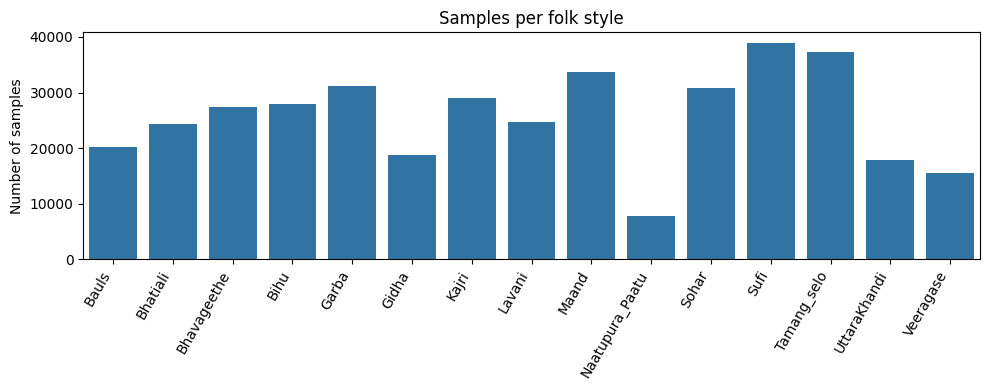

[NOTE] Noticeable class imbalance. Consider class_weight in the loss function, or oversampling the rarer styles.


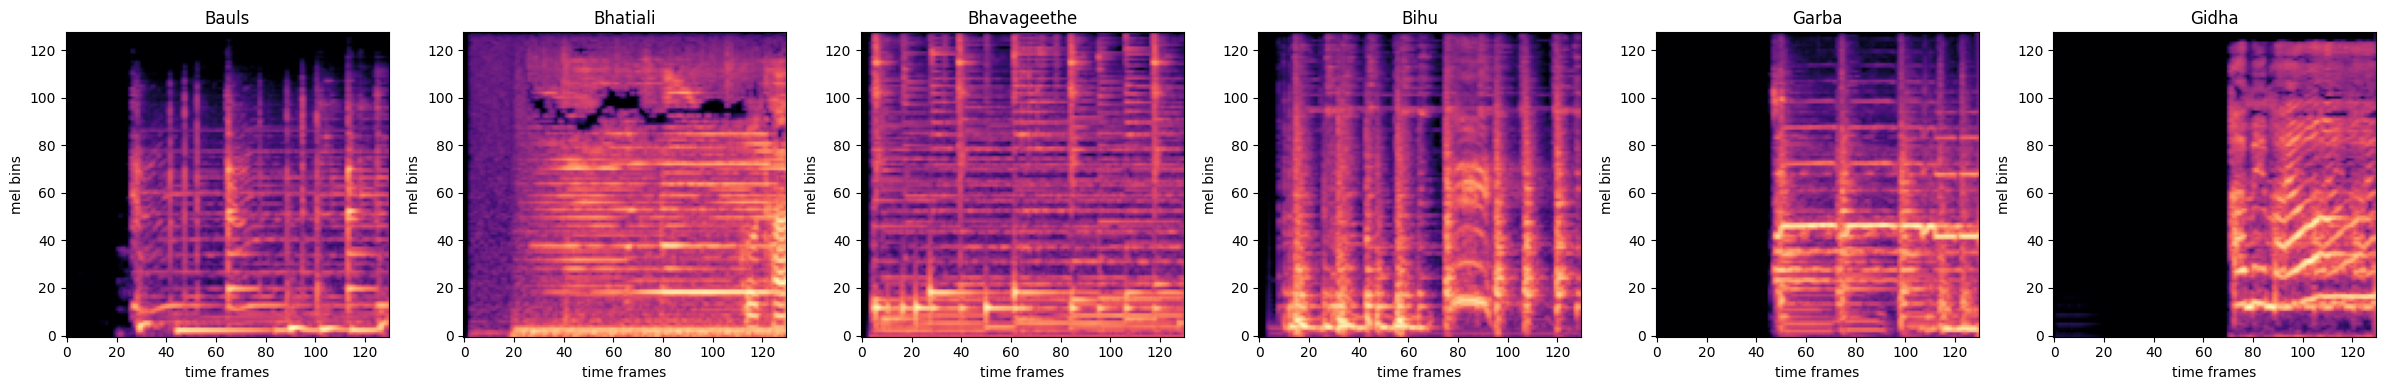

In [9]:
counts = np.bincount(y, minlength=NUM_CLASSES)

plt.figure(figsize=(10, 4))
sns.barplot(x=CLASS_NAMES, y=counts)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Number of samples")
plt.title("Samples per folk style")
plt.tight_layout()
plt.show()

if counts.max() > 2 * counts.min():
    print("[NOTE] Noticeable class imbalance. Consider class_weight in the loss "
          "function, or oversampling the rarer styles.")



n_show = min(6, NUM_CLASSES)
fig, axes = plt.subplots(1, n_show, figsize=(4 * n_show, 4))

for i in range(n_show):
    idx = y.index(i)  # first sample belonging to class i
    axes[i].imshow(X[idx], origin="lower", aspect="auto", cmap="magma")
    axes[i].set_title(CLASS_NAMES[i])
    axes[i].set_xlabel("time frames")
    axes[i].set_ylabel("mel bins")

plt.tight_layout()
plt.show()

# 5. preprocessing functions

In [10]:
def standardize(spec):
    return (spec - spec.mean()) / (spec.std() + 1e-6)

def fix_length(spec, target_frames=TARGET_FRAMES):
    n_mels, n_frames = spec.shape
    if n_frames == target_frames:
        return spec
    if n_frames > target_frames:
        start = (n_frames - target_frames) // 2
        return spec[:, start:start + target_frames]
    pad_total = target_frames - n_frames
    pad_left = pad_total // 2
    pad_right = pad_total - pad_left
    return np.pad(spec, ((0, 0), (pad_left, pad_right)), mode="constant")

def spec_augment(spec):
    spec = spec.copy()
    n_mels, n_frames = spec.shape

    f0 = np.random.randint(0, max(1, n_mels - 10))
    spec[f0:f0 + 10, :] = 0.0   # frequency mask

    t0 = np.random.randint(0, max(1, n_frames - 15))
    spec[:, t0:t0 + 15] = 0.0   # time mask

    return spec

# 6. Visual sanity check: original vs. standardized+augmented, side by side

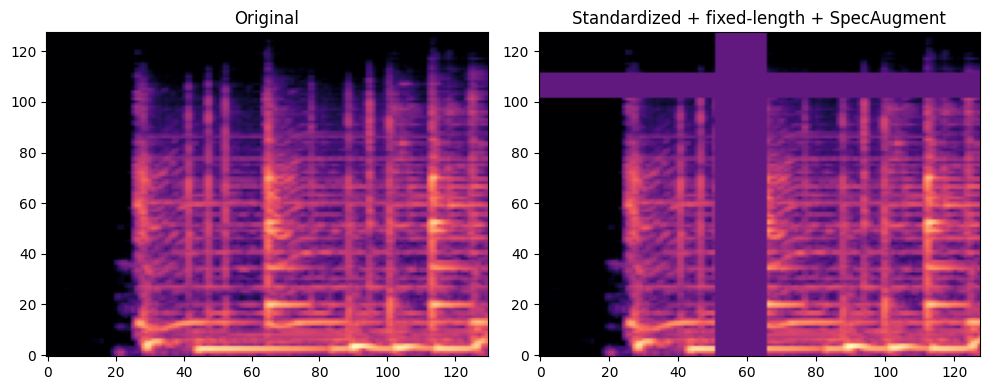

In [11]:
sample = X[0]
augmented = spec_augment(fix_length(standardize(sample)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(sample, origin="lower", aspect="auto", cmap="magma")
axes[0].set_title("Original")
axes[1].imshow(augmented, origin="lower", aspect="auto", cmap="magma")
axes[1].set_title("Standardized + fixed-length + SpecAugment")
plt.tight_layout()
plt.show()

In [ ]:
import torchaudio

class MelSpecDataset(Dataset):

    def __init__(self, X, y, train=False):

        self.X = X
        self.y = y
        self.train = train

        # SpecAugment transforms
        self.freq_mask = torchaudio.transforms.FrequencyMasking(freq_mask_param=15)
        self.time_mask = torchaudio.transforms.TimeMasking(time_mask_param=30)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        spec = torch.tensor(self.X[idx], dtype=torch.float32)

        # Add channel dimension
        spec = spec.unsqueeze(0)

        if self.train:
            spec = self.freq_mask(spec)
            spec = self.time_mask(spec)

        return spec, self.y[idx]

# 7. Train-Test Split

```python
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=VAL_SPLIT, random_state=SEED, stratify=y
)

train_ds = MelSpecDataset(X_train, y_train, train=True)
val_ds = MelSpecDataset(X_val, y_val, train=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_ds)} | Validation samples: {len(val_ds)}")```

In [30]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    test_size=VAL_SPLIT,
    random_state=SEED
)

train_idx, val_idx = next(
    gss.split(X, y, groups=songs)
)

X_train = [X[i] for i in train_idx]
y_train = [y[i] for i in train_idx]

X_val = [X[i] for i in val_idx]
y_val = [y[i] for i in val_idx]

train_ds = MelSpecDataset(X_train, y_train, train=True)
val_ds = MelSpecDataset(X_val, y_val, train=False)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# 8. Model : Resnet18 
### *architecture diagram :*
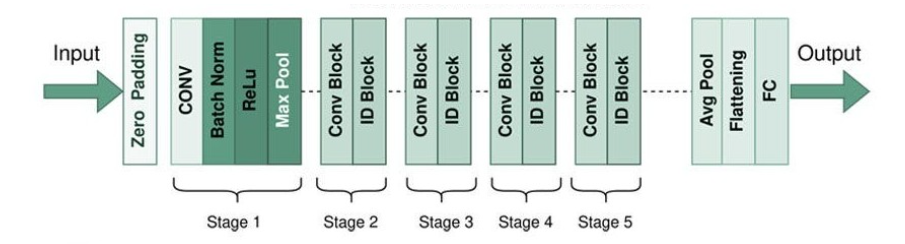

In [31]:
def build_model(arch, num_classes):
    if arch == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif arch == "resnet34":
        model = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif arch == "alexnet":
        model = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)
    else:
        raise ValueError(f"Unknown arch '{arch}'")
    return model


def freeze_backbone(model, arch):
    for param in model.parameters():
        param.requires_grad = False
    if arch.startswith("resnet"):
        for param in model.fc.parameters():
            param.requires_grad = True
    elif arch == "alexnet":
        for param in model.classifier[6].parameters():
            param.requires_grad = True
    return model


model = build_model(ARCH, NUM_CLASSES).to(DEVICE)
if FREEZE_BACKBONE:
    model = freeze_backbone(model, ARCH)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
trainable_params = filter(lambda p: p.requires_grad, model.parameters())
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR,
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=2
)

n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_trainable:,} / {n_total:,}")

Trainable parameters: 11,184,207 / 11,184,207


In [32]:
def run_epoch(model, loader, criterion, optimizer, device, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    # Progress bar for batches
    pbar = tqdm(
        loader,
        desc="Training" if train else "Validation",
        leave=False
    )

    with torch.set_grad_enabled(train):
        for inputs, labels in pbar:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * inputs.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += inputs.size(0)

            pbar.set_postfix({
                "loss": f"{loss.item():.4f}",
                "acc": f"{correct/total:.3f}"
            })

    return total_loss / total, correct / total

In [33]:
train_song_set = {songs[i] for i in train_idx}
val_song_set = {songs[i] for i in val_idx}

print("Common songs:", len(train_song_set & val_song_set))

Common songs: 0


In [ ]:
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0

for epoch in tqdm(range(EPOCHS), desc="Epochs"):

    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE,
        train=True
    )

    val_loss, val_acc = run_epoch(
        model,
        val_loader,
        criterion,
        optimizer,
        DEVICE,
        train=False
    )

    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} "
        f"train_acc={train_acc:.3f} | "
        f"val_loss={val_loss:.4f} "
        f"val_acc={val_acc:.3f}"
    )

    if val_acc > best_val_acc:

    best_val_acc = val_acc
    counter = 0

    torch.save(model.state_dict(), CHECKPOINT_PATH)

else:

    counter += 1

if counter >= patience:

    print("Early stopping!")
    break

print(f"\nBest validation accuracy: {best_val_acc:.3f}")
print(f"Best checkpoint saved to: {CHECKPOINT_PATH}")

Epochs:   0%|          | 0/25 [00:00<?, ?it/s]

Training:   0%|          | 0/19437 [00:00<?, ?it/s]

Validation:   0%|          | 0/4660 [00:00<?, ?it/s]

Epoch 01/25 | train_loss=0.1782 train_acc=0.946 | val_loss=1.6665 val_acc=0.703


Training:   0%|          | 0/19437 [00:00<?, ?it/s]

...

Epoch 19/25 | train_loss=0.0052 train_acc=0.998 | val_loss=2.9250 val_acc=0.741


Training:   0%|          | 0/19437 [00:00<?, ?it/s]

Validation:   0%|          | 0/4660 [00:00<?, ?it/s]

Epoch 20/25 | train_loss=0.0052 train_acc=0.998 | val_loss=2.9429 val_acc=0.739


Training:   0%|          | 0/19437 [00:00<?, ?it/s]